In [ ]:
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt


def generate_maintenance_plan(N, T, random_seed, alpha_range=(0.001, 0.05), initial_p_range=(3.2, 3.5)):
    """生成维护计划"""
    caissons = [i for i in range(N)]
    
    random.seed(random_seed)
    alpha_values = [round(random.uniform(*alpha_range), 6) for _ in range(N)]
    
    random.seed(random_seed+1)
    initial_p_values = [round(random.uniform(*initial_p_range), 2) for _ in range(N)]
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    
    index = 0
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            operation = 'x'
            data.append([index, caisson, initial_p_values[caisson], operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values


def run_clustering_analysis(params, random_seed):
    """完整聚类分析函数"""
    # 生成维护计划
    df, alpha_values_list = generate_maintenance_plan(
        N=params['P'], T=params['T'], random_seed=random_seed
    )
    print(f"Generated {len(df)} tasks for seed {random_seed}")
    
    # alpha_values字典格式
    alpha_values = {i: alpha_values_list[i] for i in range(params['P'])}
    globals()['alpha_values'] = alpha_values
    globals()['PARAMS'] = params

    # 🔥 新增：整个聚类过程CPU时间测量
    import time
    clustering_cpu_start = time.process_time()
    
    # 聚类函数
    def clustering_CR(df_window, window_size, window_start):
        if df_window.empty or window_size < 1:
            print(f"warning: window {window_start} has no tasks")
            return df_window

        N_tasks = df_window.shape[0]
        m = gp.Model('Dynamic_Window_Clustering')
        m.setParam('OutputFlag', 0)
        
        data_pos_num = window_size + 1
        theta = m.addVars(N_tasks, data_pos_num, vtype=GRB.BINARY, name='theta')
        cluster = m.addVars(data_pos_num, vtype=GRB.BINARY, name='cluster')

        a = [0] * N_tasks
        b = [0] * N_tasks

        m.setObjective(gp.quicksum(cluster[t] for t in range(data_pos_num)), GRB.MINIMIZE)
        
        m.addConstrs((theta[n, t] <= cluster[t] for n in range(N_tasks) for t in range(data_pos_num)), 
                     name="cluster_activation")
        m.addConstrs((gp.quicksum(theta[n, t] for t in range(data_pos_num)) == 1 for n in range(N_tasks)), 
                     name="task_assignment")
        m.addConstrs((gp.quicksum(theta[n, t] for n in range(N_tasks)) <= PARAMS['Cmax'] for t in range(data_pos_num)), 
                     name="cluster_capacity")

        for n in range(N_tasks):
            csem = int(df_window.iloc[n]['CSEM'])
            local_time = df_window.iloc[n]['window_time']
            a[n] = max(0, local_time - PARAMS['advanced'])
            alpha = alpha_values[csem]
            b[n] = min(data_pos_num, (local_time + int(0.2 / alpha))//2)

        for n in range(N_tasks):
            for t in range(data_pos_num):
                m.addConstr(t * theta[n,t] + a[n] * (1 - theta[n, t]) >= a[n])
                m.addConstr(t * theta[n,t] + b[n] * (1 - theta[n, t]) <= b[n])

        m.setParam('LogToConsole', 1)
        m.setParam('OutputFlag', 1)
        m.setParam('TimeLimit', 300)
        m.setParam('MIPGap', 0.05)

        print(f"Window {window_start}: N_tasks={N_tasks}")
        m.optimize()

        if m.status != GRB.OPTIMAL:
            print(f"Failed to solve window {window_start}: {m.status}")
            return None
        
        centers = {}
        for n in range(N_tasks):
            for t in range(data_pos_num):
                if theta[n, t].x == 1.0:
                    centers[n] = t + window_start
                    break

        index_n_list = df_window.INDEX.tolist()
        for n in range(len(index_n_list)):
            df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

        return df_window
    
    # 泄漏计算函数
    def calculate_gas_leakage(df, T, use_center=True):
        total_leakage = 0
        for csem in df['CSEM'].unique():
            csem_data = df[df['CSEM'] == csem]
            x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
            if x_operations.empty:
                continue
                
            alpha = alpha_values[int(csem)]

            # 任务间泄漏
            for i in range(1, len(x_operations)):
                current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
                prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
                center_diff = current_time - prev_time - 1
                total_leakage += max(0, center_diff) * alpha * PARAMS['K']

            # 开头泄漏
            first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
            total_leakage += first_time * alpha * PARAMS['K']

            # 结尾泄漏
            last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
            leak_time = max(0, T - (last_time + 1))
            total_leakage += leak_time * alpha * PARAMS['K']
        return total_leakage
    
    # 更新次要任务函数
    def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
        for caisson in clustered_df["CSEM"].unique():
            tasks = main_df[
                (main_df['CSEM'] == caisson) & 
                (main_df['DATE'].between(window_start, window_end)) & 
                (main_df['OPERATION'] == 'x')
            ]
            if len(tasks) > 1:
                second_idx = tasks.index[1]
                center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
                alpha = alpha_values[int(caisson)]
                new_date = int(center_time + 1 + (3.5-3.2)/alpha)
                main_df.loc[second_idx, ['DATE', 'CENTER']] = [new_date, new_date]

    # 主逻辑
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']

    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        clustered_df = clustering_CR(first_tasks, window_size, window_start)
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # 滑动窗口逻辑
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    # 🔥 聚类过程CPU时间结束
    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start


    # 计算泄漏
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list,
        'maintenance_plan': df_init,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }


def calculate_detailed_stats(result_dict, params):
    """
    计算所有详细指标，用于CSV输出
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务，确保INDEX对齐
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # CP成本计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    cp_cost = np.sum(
        np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], time_diffs * params['Cbeta'])
    )
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = num_advanced / num_tasks * params['Cs']
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = num_delayed / num_tasks * params['Cs']
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = num_unchanged / num_tasks * params['Cs']
    
    # 成本统计
    operation_x_count = len(df_x)
    cs_cost_before = operation_x_count * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    cs_cost_reduction = cs_cost_before - cs_cost_after
    cs_cost_reduction_pct = cs_cost_reduction / cs_cost_before * 100
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计（来自result_dict）
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']

    # 🔥 整个聚类过程CPU时间
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 完整统计字典（匹配你的表格列）
    stats = {
        # 基本信息
        'seed': None,  # 稍后填充
        'nb_groups': num_groups,
        'Avg_tasks/group': avg_tasks_per_group,
        
        # CP成本
        'CP_cost': cp_cost,
        
        # 时间偏移
        'Avg_shift_(abs)': avg_shift_abs,
        'Max_shift_(abs)': max_shift_abs,
        'Avg_advance_(days)': avg_advance,
        'Avg_delay_(days)': avg_delay,
        'pct_advanced_%': pct_advanced,
        'pct_delayed_%': pct_delayed,
        'pct_unchanged_%': pct_unchanged,
        'num_advanced': num_advanced,
        'num_delayed': num_delayed,
        'num_unchanged': num_unchanged,
        'total_tasks': num_tasks,
        
        # CS成本
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        # 'CS_cost_reduction': cs_cost_reduction,
        # 'CS_cost_reduction_pct': cs_cost_reduction_pct,

        # Total成本
        'Total_cost': total_cost,
        
        # 泄漏统计
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'leakage_reduction': leakage_reduction,
        'leakage_reduction_pct': leakage_reduction_pct,

        # CPU时间
        'total_clustering_cpu_s': total_clustering_cpu_time,
    }
    
    return stats


def run_analysis_with_csv_export(params, seeds, output_filename='detailed_results.csv'):
    """
    运行多种子分析并导出完整CSV（包含所有表格列）
    """
    all_results = []
    
    for seed in seeds:
        print(f"\n🔄 Processing seed {seed}...")
        
        # 运行分析
        result_dict = run_clustering_analysis(params, random_seed=seed)
        
        # 计算详细统计
        stats = calculate_detailed_stats(result_dict, params)
        stats['seed'] = seed  # 填充seed信息
        
        all_results.append(stats)
        
        # 打印摘要
        print(f"✅ Seed {seed}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
    
    # 转换为DataFrame并排序列顺序（匹配你的表格）
    results_df = pd.DataFrame(all_results)
    
    # 按你的截图调整列顺序
    column_order = [
        'seed', 'nb_groups', 'Avg_tasks/group',  'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost',
        'Avg_shift_(abs)', 'Max_shift_(abs)', 'Avg_advance_(days)', 'Avg_delay_(days)','pct_advanced_%', 
        'pct_delayed_%', 'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction', 
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 只保留存在的列并排序
    available_columns = [col for col in column_order if col in results_df.columns]
    results_df = results_df[available_columns]
    
    # 保存CSV
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    print(f"\n📁 完整结果已保存到: {output_filename}")
    print(f"📊 包含 {len(results_df)} 种子, {len(results_df.columns)} 个指标列")
    
    return results_df


def visualize_clustering_results(result_dict, params, seed_name="default", save_csv=True, show_plot=True):
    """可视化聚类结果"""
    result_df = result_dict['final_df']
    maintenance_plan = result_dict['maintenance_plan']
    
    # 成本计算
    operation_x_count = (result_df['OPERATION'] == 'x').sum()
    before_cost = operation_x_count * params['Cs'] 
    operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
    after_cost = operation_x_center_unique_count * params['Cs'] 
    
    print(f"Cost before grouping: {before_cost}")
    print(f"Cost after grouping: {after_cost}")
    
    # 泄漏统计
    leakage_before = round(result_dict['leakage_before'], 3)
    leakage_after = round(result_dict['leakage_after'], 3)
    print(f"Gas leakage before: {leakage_before}")
    print(f"Gas leakage after: {leakage_after}")
    
    # 节约统计
    cost_reduction = before_cost - after_cost
    cost_reduction_pct = (cost_reduction / before_cost * 100) if before_cost > 0 else 0
    print(f"Cost reduction: {cost_reduction} ({cost_reduction_pct:.1f}%)")
    print(f"Gas leakage reduction: {result_dict['reduction']:.3f} ({result_dict['reduction_pct']:.1f}%)")
    
    # 计算统计指标（修复UnboundLocalError）
    result_df_x_count = len(result_df[result_df['OPERATION'] == 'x'])
    avg_tasks_per_cluster = result_df_x_count / operation_x_center_unique_count if operation_x_center_unique_count > 0 else 0
    
    if show_plot:
        plt.figure(figsize=(8, 7))
        
        df_original_x = maintenance_plan[maintenance_plan['OPERATION'] == 'x']
        result_df_x = result_df[result_df['OPERATION'] == 'x']
        
        df_x = df_original_x.set_index('INDEX')
        result_x = result_df_x.set_index('INDEX')
        common_indices = df_x.index.intersection(result_x.index)
        df_x = df_x.loc[common_indices].reset_index()
        result_x = result_x.loc[common_indices].reset_index()
        
        time_shift = result_x['CENTER'] - df_x['DATE']
        plt.scatter(df_x['DATE'], result_x['CENTER'], 
                   c=time_shift, cmap='RdBu_r', 
                   vmin=-max(abs(time_shift.min()), abs(time_shift.max())), 
                   vmax=max(abs(time_shift.min()), abs(time_shift.max())), 
                   alpha=0.7, s=50, edgecolors='black', linewidth=0.8)
        
        plt.colorbar(label='Time Shift (days)\nRed=delayed, Blue=advanced')
        plt.title(f"Cluster Center Distribution (Seed {seed_name})", fontsize=16, fontweight='bold')
        plt.xlabel("Original time", fontsize=14)
        plt.ylabel("Cluster center", fontsize=14)
        plt.grid(True, alpha=0.3)
        
        max_range = max(result_x['DATE'].max(), result_x['CENTER'].max() + 5)
        plt.xlim(0, max_range)
        plt.ylim(0, max_range)
        plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', linewidth=2, label='45° diagonal')
        plt.legend()
        plt.gca().set_aspect('equal')
        plt.tight_layout()
        plt.show()
        
        center_counts = result_df_x['CENTER'].value_counts().sort_index()
        print("\nCluster center usage:")
        print(center_counts)
        print(f"Total clusters used: {len(center_counts)}")
        print(f"Average tasks per cluster: {avg_tasks_per_cluster:.1f}")
    
    if save_csv:
        filename = f'optimized_plan_seed_{seed_name}.csv'
        result_df.to_csv(filename, index=False)
        print(f"\nResult saved to '{filename}'")
    
    print(f"\nSummary:")
    print(f"- Cost saved: {cost_reduction_pct:.1f}%")
    print(f"- Gas leakage reduced: {result_dict['reduction_pct']:.1f}%")
    print(f"- Clusters created: {operation_x_center_unique_count}")


    return {
        'before_cost': before_cost,
        'after_cost': after_cost,
        'cost_reduction': cost_reduction,
        'cost_reduction_pct': cost_reduction_pct,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'clusters_used': operation_x_center_unique_count,
        'avg_tasks_per_cluster': avg_tasks_per_cluster
    }


# # 使用示例 - 生成你的表格CSV if we fixed P and iterate seeds
# params = {
#     'P': 100, 
#     'T': 180, 
#     'Cmax': 20, 
#     'window_size': 10, 
#     'advanced': 3, 
#     'K': 5.993, 
#     'Calpha': 5, 
#     'Cbeta': 10, 
#     'Cs': 100}

# seeds_to_test = [40]

# # name the file if sensitivity for P
# detailed_results_df = run_analysis_with_csv_export(
#     params, seeds_to_test, 
#     output_filename=f'Sensitivity_N/Summary_results_P{params["P"]}.csv'
# )

# # 显示前几行
# print("\n📋 CSV预览:")
# print(detailed_results_df.round(3).head())
# visualize_clustering_results(
#     run_clustering_analysis(params, random_seed=40),
#     params, seed_name=40, save_csv=False, show_plot=True)



# # 🔥 新实验：固定seed=1，P从10-200循环
# for seed in range(1, 31):  
#     P_values = list(range(10, 201, 10))  # 10,20,...,200，共19个值

#     base_params = {
#         'T': 180, 
#         'Cmax': 20, 
#         'window_size': 10, 
#         'advanced': 3, 
#         'K': 5.993, 
#         'Calpha': 5, 
#         'Cbeta': 10, 
#         'Cs': 100
#     }

#     all_results = []

#     for p in P_values:
#         print(f"\n🔄 Running P={p} with seed={seed}...")
        
#         params = base_params.copy()
#         params['P'] = p  # 更新P
        
#         # 运行分析（单seed）
#         result_dict = run_clustering_analysis(params, random_seed=seed)
#         stats = calculate_detailed_stats(result_dict, params)
#         stats['seed'] = seed
#         stats['P'] = p  # 添加P列
        
#         all_results.append(stats)
        
#         print(f"✅ P={p}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")

#     # DataFrame并保存
#     results_df = pd.DataFrame(all_results)

#     # 🔥 你以前的精确列顺序（从CSV头）
#     original_column_order = [
#         'seed', 'nb_groups', 'Avg_tasks/group', 
#         'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
#         'Avg_shift_(abs)', 'Max_shift_(abs)', 
#         'Avg_advance_(days)', 'Avg_delay_(days)', 
#         'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
#         'leakage_before', 'leakage_after', 'leakage_reduction', 'leakage_reduction_pct', 
#         'total_clustering_cpu_s'
#     ]

#     # 🔥 P放最前，其余严格按原顺序
#     column_order = ['P'] + original_column_order
#     available_columns = [col for col in column_order if col in results_df.columns]
#     results_df = results_df[available_columns]

#     filename = f'Sensitivity_P10-200_seed{seed}_all_metrics.csv'
#     results_df.to_csv(filename, index=False, float_format='%.3f')
#     print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")

#     # 显示预览
#     print("\n📋 结果预览:")
#     print(results_df.round(3)[['P', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))

#     # 可视化最后一个P的结果
#     visualize_clustering_results(
#         run_clustering_analysis({**base_params, 'P': 200}, random_seed=seed),
#         {**base_params, 'P': 200}, seed_name=f"{seed}_P200", save_csv=True)



# # 🔥 新实验：固定seed=1，T从10-200循环
# seed = 32  # 固定单一seed
# T_values = list(range(30, 361, 30))  # 30,60,...,360，共12个值

# base_params = {
#     'P': 100, 
#     'Cmax': 20, 
#     'window_size': 10, 
#     'advanced': 3, 
#     'K': 5.993, 
#     'Calpha': 5, 
#     'Cbeta': 10, 
#     'Cs': 100
# }

# all_results = []

# for t in T_values:
#     print(f"\n🔄 Running T={t} with seed={seed}...")
    
#     params = base_params.copy()
#     params['T'] = t  # 更新T
    
#     # 运行分析（单seed）
#     result_dict = run_clustering_analysis(params, random_seed=seed)
#     stats = calculate_detailed_stats(result_dict, params)
#     stats['seed'] = seed
#     stats['T'] = t  # 添加T列
    
#     all_results.append(stats)
    
#     print(f"✅ T={t}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")

# # DataFrame并保存
# results_df = pd.DataFrame(all_results)

# # 🔥 你以前的精确列顺序（从CSV头）
# original_column_order = [
#     'seed', 'nb_groups', 'Avg_tasks/group', 
#     'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
#     'Avg_shift_(abs)', 'Max_shift_(abs)', 
#     'Avg_advance_(days)', 'Avg_delay_(days)', 
#     'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
#     'leakage_before', 'leakage_after', 'leakage_reduction', 'leakage_reduction_pct', 
#     'total_clustering_cpu_s'
# ]

# # 🔥 P放最前，其余严格按原顺序
# column_order = ['T'] + original_column_order
# available_columns = [col for col in column_order if col in results_df.columns]
# results_df = results_df[available_columns]

# filename = f'Sensitivity_T30-360_seed{seed}_all_metrics.csv'
# results_df.to_csv(filename, index=False, float_format='%.3f')
# print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")

# # 显示预览
# print("\n📋 结果预览:")
# print(results_df.round(3)[['T', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))

# # 可视化最后一个P的结果
# visualize_clustering_results(
#     run_clustering_analysis({**base_params, 'T': 360}, random_seed=seed),
#     {**base_params, 'T': 360}, seed_name=f"{seed}_T360", save_csv=True)




# import time
# import threading
# import pandas as pd  # 确保导入

# # 🔥 配置（你的原始参数）
# P_values = list(range(10, 201, 10))
# PARAMS = {
#     'T': 180, 
#     'Cmax': 20, 
#     'window_size': 10, 
#     'advanced': 3, 
#     'K': 5.993, 
#     'Calpha': 5, 
#     'Cbeta': 10, 
#     'Cs': 100
# }

# TIMEOUT_SECONDS_PER_SEED = 180  # 3分钟
# MAX_ATTEMPTS = 50
# TARGET_SEEDS = 30

# class SeedTimeoutException(Exception):
#     pass

# def seed_timeout_monitor(stop_event):
#     time.sleep(TIMEOUT_SECONDS_PER_SEED)
#     stop_event.set()
#     raise SeedTimeoutException("Seed超时3分钟")

# # 🔥 初始化变量
# successful_count = 0

# print(f"🚀 Seed超时保护版 - 目标{ TARGET_SEEDS }个完整结果")

# # 🔥 你的原始循环结构 + 超时保护
# for seed_attempt in range(MAX_ATTEMPTS):
#     if successful_count >= TARGET_SEEDS:
#         break
        
#     seed = seed_attempt + 1
#     print(f"\n🔄 Processing seed {seed}... (总超时3min)")
    
#     # 🔥 Seed超时监控
#     stop_event = threading.Event()
#     timeout_thread = threading.Thread(target=seed_timeout_monitor, args=(stop_event,))
#     timeout_thread.daemon = True
#     timeout_thread.start()
    
#     all_results = []
#     seed_success = True
    
#     try:
#         for p in P_values:
#             if stop_event.is_set():
#                 print(f"\n⏰ Seed={seed} 总超时3分钟，换下一个seed！")
#                 seed_success = False
#                 break
            
#             print(f"\n🔄 Running P={p} with seed={seed}...")
            
#             params = PARAMS.copy()
#             params['P'] = p
            
#             # 🔥 无P超时，直接运行你的函数
#             result_dict = run_clustering_analysis(params, random_seed=seed)
#             stats = calculate_detailed_stats(result_dict, params)
#             stats['seed'] = seed
#             stats['P'] = p
#             all_results.append(stats)
            
#             print(f"✅ P={p}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
        
#         # 🔥 停止超时线程
#         stop_event.set()
#         timeout_thread.join(timeout=1)
        
#         if seed_success and len(all_results) == len(P_values):
#             # 🔥 🔥 🔥 完全你的原始保存逻辑！
#             results_df = pd.DataFrame(all_results)
            
#             # 🔥 你以前的精确列顺序
#             original_column_order = [
#                 'seed', 'nb_groups', 'Avg_tasks/group', 
#                 'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
#                 'Avg_shift_(abs)', 'Max_shift_(abs)', 
#                 'Avg_advance_(days)', 'Avg_delay_(days)', 
#                 'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
#                 'leakage_before', 'leakage_after', 'leakage_reduction', 
#                 'leakage_reduction_pct', 'total_clustering_cpu_s'
#             ]
            
#             # 🔥 P放最前，完全一样！
#             column_order = ['P'] + original_column_order
#             available_columns = [col for col in column_order if col in results_df.columns]
#             results_df = results_df[available_columns]
            
#             # 🔥 🔥 完全一样的文件名！
#             filename = f'Sensitivity_P_MIMAR/Sensitivity_P10-200_seed{seed}_MIMAR.csv'
#             results_df.to_csv(filename, index=False, float_format='%.3f')
#             print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")
            
#             # 🔥 你的预览，完全一样！
#             print("\n📋 结果预览:")
#             print(results_df.round(3)[['P', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))
            
#             # # 🔥 你的可视化，完全一样！
#             # visualize_clustering_results(
#             #     run_clustering_analysis({**base_params, 'P': 200}, random_seed=seed),
#             #     {**base_params, 'P': 200}, seed_name=f"{seed}_P200", save_csv=True
#             # )
            
#             successful_count += 1
#             print(f"✅ Seed={seed} 完美！进度：{successful_count}/{TARGET_SEEDS}")
#         else:
#             print(f"❌ Seed={seed} 超时中断，尝试下一个...")
            
#     except Exception as e:
#         print(f"💥 Seed={seed} 异常：{str(e)}")
#         stop_event.set()
#         timeout_thread.join(timeout=1)

# print(f"\n🎉 批量实验完成！成功{successful_count}/{TARGET_SEEDS}个seed")



import time
import threading
import pandas as pd  # 确保导入


# 🔥 配置（修改：固定P=100，T从30-360每隔30）
T_values = list(range(30, 361, 30))  # 30,60,90,...,360
PARAMS = {
    'P': 100,  # 固定P=100
    'Cmax': 20, 
    'window_size': 10, 
    'advanced': 3, 
    'K': 5.993, 
    'Calpha': 5, 
    'Cbeta': 10, 
    'Cs': 100
}


TIMEOUT_SECONDS_PER_SEED = 180  # 3分钟
MAX_ATTEMPTS = 50
TARGET_SEEDS = 30


class SeedTimeoutException(Exception):
    pass


def seed_timeout_monitor(stop_event):
    time.sleep(TIMEOUT_SECONDS_PER_SEED)
    stop_event.set()
    raise SeedTimeoutException("Seed超时3分钟")


# 🔥 初始化变量
successful_count = 0


print(f"🚀 Seed超时保护版 - 固定P=100，T=30-360 - 目标{ TARGET_SEEDS }个完整结果")


# 🔥 你的原始循环结构 + 超时保护
for seed_attempt in range(MAX_ATTEMPTS):
    if successful_count >= TARGET_SEEDS:
        break
        
    seed = seed_attempt + 1
    print(f"\n🔄 Processing seed {seed}... (总超时3min)")
    
    # 🔥 Seed超时监控
    stop_event = threading.Event()
    timeout_thread = threading.Thread(target=seed_timeout_monitor, args=(stop_event,))
    timeout_thread.daemon = True
    timeout_thread.start()
    
    all_results = []
    seed_success = True
    
    try:
        for t in T_values:
            if stop_event.is_set():
                print(f"\n⏰ Seed={seed} 总超时3分钟，换下一个seed！")
                seed_success = False
                break
            
            print(f"\n🔄 Running T={t} with seed={seed}...")
            
            params = PARAMS.copy()
            params['T'] = t
            
            # 🔥 无T超时，直接运行你的函数
            result_dict = run_clustering_analysis(params, random_seed=seed)
            stats = calculate_detailed_stats(result_dict, params)
            stats['seed'] = seed
            stats['T'] = t  # 修改为T
            all_results.append(stats)
            
            print(f"✅ T={t}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
        
        # 🔥 停止超时线程
        stop_event.set()
        timeout_thread.join(timeout=1)
        
        if seed_success and len(all_results) == len(T_values):
            # 🔥 🔥 🔥 完全你的原始保存逻辑！
            results_df = pd.DataFrame(all_results)
            
            # 🔥 你以前的精确列顺序（添加T）
            original_column_order = [
                'seed', 'nb_groups', 'Avg_tasks/group', 
                'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
                'Avg_shift_(abs)', 'Max_shift_(abs)', 
                'Avg_advance_(days)', 'Avg_delay_(days)', 
                'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
                'leakage_before', 'leakage_after', 'leakage_reduction', 
                'leakage_reduction_pct', 'total_clustering_cpu_s'
            ]
            
            # 🔥 T放最前，完全一样！
            column_order = ['T'] + original_column_order  # 修改为T
            available_columns = [col for col in column_order if col in results_df.columns]
            results_df = results_df[available_columns]
            
            # 🔥 🔥 修改文件名：Sensitivity_T_MIMAR
            filename = f'Sensitivity_T_MIMAR/Sensitivity_T30-360_seed{seed}_MIMAR.csv'
            results_df.to_csv(filename, index=False, float_format='%.3f')
            print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")
            
            # 🔥 你的预览，显示T列
            print("\n📋 结果预览:")
            print(results_df.round(3)[['T', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))
            
            successful_count += 1
            print(f"✅ Seed={seed} 完美！进度：{successful_count}/{TARGET_SEEDS}")
        else:
            print(f"❌ Seed={seed} 超时中断，尝试下一个...")
            
    except Exception as e:
        print(f"💥 Seed={seed} 异常：{str(e)}")
        stop_event.set()
        timeout_thread.join(timeout=1)


print(f"\n🎉 批量实验完成！成功{successful_count}/{TARGET_SEEDS}个seed")



🚀 Seed超时保护版 - 固定P=100，T=30-360 - 目标30个完整结果

🔄 Processing seed 1... (总超时3min)

🔄 Running T=30 with seed=1...
Generated 243 tasks for seed 1
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 0: N_tasks=75
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2561 rows, 836 columns and 4805 nonzeros
Model fingerprint: 0x218633d8
Variable types: 0 continuous, 836 integer (836 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Found heuristic solution: objective 10.0000000
Presolve removed 2175 rows and 520 columns
Presolve time: 0.00s
Presolved: 386 rows, 316 columns, 1195 nonzeros
Variable types: 0 continuous, 316 integer (316 binary)

Root relaxation: objective 3.258065e+00, 3

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 14: N_tasks=74
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2527 rows, 825 columns and 4740 nonzeros
Model fingerprint: 0xe1d1e447
Variable types: 0 continuous, 825 integer (825 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Found heuristic solution: objective 10.0000000
Presolve removed 2147 rows and 515 columns
Presolve time: 0.00s
Presolved: 380 rows, 310 columns, 1181 nonzeros
Variable types: 0 continuous, 310 integer (310 binary)

Root relaxation: objective 3.209302e+00, 362 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Ob

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 0: N_tasks=75
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2561 rows, 836 columns and 4805 nonzeros
Model fingerprint: 0x218633d8
Variable types: 0 continuous, 836 integer (836 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Found heuristic solution: objective 10.0000000
Presolve removed 2175 rows and 520 columns
Presolve time: 0.00s
Presolved: 386 rows, 316 columns, 1195 nonzeros
Variable types: 0 continuous, 316 integer (316 binary)

Root relaxation: objective 3.258065e+00, 340 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

... (7,850 outputs left out)

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 350: N_tasks=77
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2629 rows, 858 columns and 4933 nonzeros
Model fingerprint: 0x0bac9435
Variable types: 0 continuous, 858 integer (858 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Found heuristic solution: objective 11.0000000
Presolve removed 2184 rows and 487 columns
Presolve time: 0.00s
Presolved: 445 rows, 371 columns, 1407 nonzeros
Variable types: 0 continuous, 371 integer (371 binary)

Root relaxation: objective 3.000000e+00, 299 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  O

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


✅ T=360: CP_cost=69515.0, Groups=222

📁 结果保存到: Sensitivity_T_MIMAR/Sensitivity_T30-360_seed30_MIMAR.csv (共12行，20列)

📋 结果预览:
     T  nb_groups  CP_cost  Total_cost  total_clustering_cpu_s
0   30         17     5105        6805                   0.525
1   60         33    10655       13955                   0.991
2   90         51    16865       21965                   1.720
3  120         68    22070       28870                   2.452
4  150         87    27555       36255                   2.967
5  180        109    34735       45635                   3.690
6  210        129    39880       52780                   4.411
7  240        148    46305       61105                   5.072
8  270        167    52310       69010                   5.677
9  300        183    57850       76150                   6.303
✅ Seed=30 完美！进度：30/30

🎉 批量实验完成！成功30/30个seed


Exception in thread Thread-63:
Traceback (most recent call last):
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/threading.py", line 980, in _bootstrap_inner
    self.run()
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 772, in run_closure
    _threading_Thread_run(self)
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/threading.py", line 917, in run
    self._target(*self._args, **self._kwargs)
  File "/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_18692/1014655254.py", line 804, in seed_timeout_monitor
__main__.SeedTimeoutException: Seed超时3分钟


In [3]:
# plot sensitivity P for different seeds
import pandas as pd
import glob
import os

# 指定文件夹路径
folder_path = 'Sensitivity_P_MIMAR'


# 查找所有匹配的CSV文件
pattern = os.path.join(folder_path, "Sensitivity_P10-200_seed*_all_metrics.csv")
csv_files = glob.glob(pattern)

if not csv_files:
    print("未找到匹配的CSV文件，请检查文件名模式。")
else:
    dfs = []
    for file in csv_files:
        df = pd.read_csv(file)
        dfs.append(df)

    # 垂直合并所有DataFrame（假设行数相同，对应行合并）
    combined_df = pd.concat(dfs, ignore_index=False)

    # 按行索引分组，计算每列均值（对应行平均）
    avg_df = combined_df.groupby(combined_df.index).mean()

    # 保存结果为average_results.csv，保留列名
    # avg_df.to_csv('average_results.csv')
    # print("平均结果已保存到 average_results.csv")
    print(avg_df)  # 预览前几行


        P       seed   nb_groups  Avg_tasks/group  CS_cost_before  \
0    10.0  18.366667   42.866667         3.303567    14000.000000   
1    20.0  18.366667   46.700000         6.111267    28496.666667   
2    30.0  18.366667   47.133333         9.035800    42480.000000   
3    40.0  18.366667   46.866667        12.254400    57163.333333   
4    50.0  18.366667   50.533333        14.257967    71806.666667   
5    60.0  18.366667   65.200000        13.244067    86126.666667   
6    70.0  18.366667   79.066667        12.785533   100950.000000   
7    80.0  18.366667   86.300000        13.338400   114956.666667   
8    90.0  18.366667   89.400000        14.402867   128586.666667   
9   100.0  18.366667   96.333333        14.911500   143036.666667   
10  110.0  18.366667  106.766667        14.763933   156760.000000   
11  120.0  18.366667  120.766667        14.285933   172060.000000   
12  130.0  18.366667  123.733333        15.035367   185553.333333   
13  140.0  18.366667  126.966667  

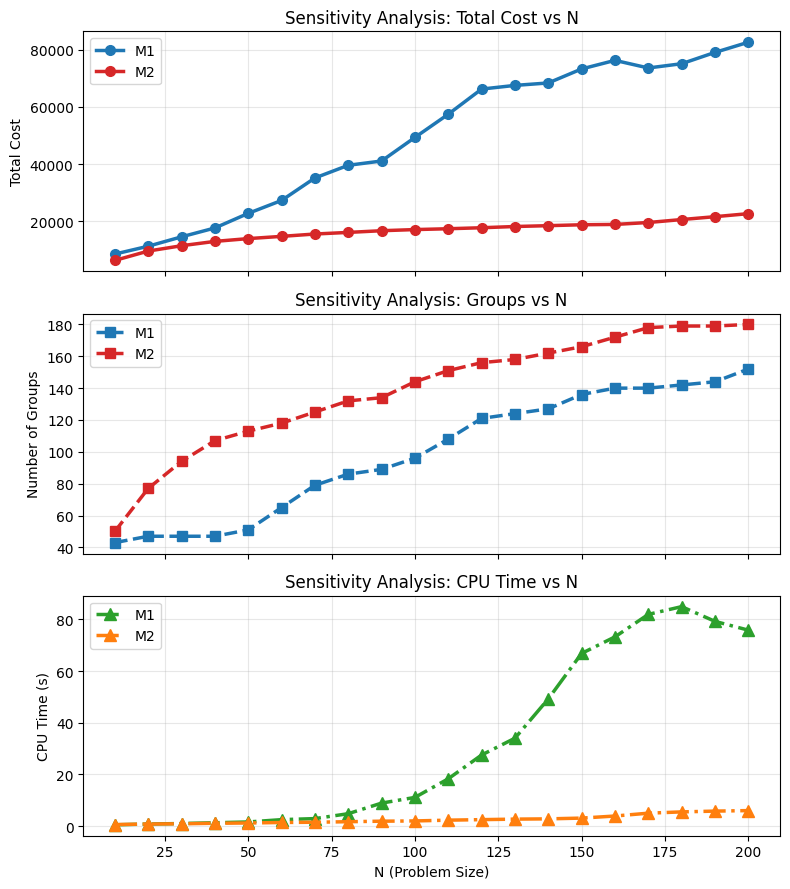

In [5]:
# sensitivity analysis for problem size: N
import matplotlib.pyplot as plt
import numpy as np

# ===== 数据 =====
N = np.arange(10, 210, 10)

# M1
total_cost_M1 = np.array([8541.50, 11281.17, 14565.67, 17662.17, 22761.00, 27276.33, 35139.50, 39574.33, 41074.17, 49307.33, 57421.83, 66214.00, 67497.83, 68352.67, 73250.50, 76246.67, 73591.83, 75075.17, 79033.33, 82584.00])
num_groups_M1 = np.array([43, 47, 47, 47, 51, 65, 79, 86, 89, 96, 108, 121, 124, 127, 136, 140, 140, 142, 144, 152])
cpu_time_M1   = np.array([0.5, 0.8, 1.0, 1.3, 1.6, 2.5, 2.9, 4.8, 8.9, 11.1, 18.3, 27.5, 34.0, 49.2, 66.8, 73.2, 81.9, 84.9, 79.2, 75.8])

# M2
total_cost_M2 = np.array([6320.00, 9589.83, 11457.50, 12970.50, 13946.33, 14726.33, 15549.83, 16114.00, 16702.83, 17101.83, 17394.83, 17744.67, 18173.17, 18467.50, 18786.17, 18898.00, 19574.17, 20607.33, 21611.67, 22667.83])
num_groups_M2 = np.array([50, 77, 94, 107, 113, 118, 125, 132, 134, 144, 151, 156, 158, 162, 166, 172, 178, 179, 179, 180])
cpu_time_M2   = np.array([0.6, 0.8, 0.9, 1.1, 1.2, 1.4, 1.5, 1.7, 1.9, 2.0, 2.3, 2.5, 2.7, 2.8, 3.1, 3.9, 5.0, 5.5, 5.8, 6.0])

plt.rcParams["font.family"] = "DejaVu Sans"

# ===== 三个子图 =====
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)

# ========== 图1：Total Cost ==========
axes[0].plot(N, total_cost_M1, "o-", color="#1f77b4", linewidth=2.5, markersize=7, label="M1")
axes[0].plot(N, total_cost_M2, "o-", color="#d62728", linewidth=2.5, markersize=7, label="M2")
axes[0].set_ylabel("Total Cost")
axes[0].set_title("Sensitivity Analysis: Total Cost vs N")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# ========== 图2：Number of Groups ==========
axes[1].plot(N, num_groups_M1, "s--", color="#1f77b4", linewidth=2.5, markersize=7, label="M1")
axes[1].plot(N, num_groups_M2, "s--", color="#d62728", linewidth=2.5, markersize=7, label="M2")
axes[1].set_ylabel("Number of Groups")
axes[1].set_title("Sensitivity Analysis: Groups vs N")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

# ========== 图3：CPU Time ==========
axes[2].plot(N, cpu_time_M1, "^-.", color="#2ca02c", linewidth=2.5, markersize=8, label="M1")
axes[2].plot(N, cpu_time_M2, "^-.", color="#ff7f0e", linewidth=2.5, markersize=8, label="M2")
axes[2].set_xlabel("N (Problem Size)")
axes[2].set_ylabel("CPU Time (s)")
axes[2].set_title("Sensitivity Analysis: CPU Time vs N")
axes[2].legend(loc="upper left")
axes[2].grid(True, alpha=0.3)

# 可选：CPU 对数轴看线性度
# axes[2].set_yscale("log")

plt.tight_layout()
plt.show()


In [1]:
# plot sensitivity T for different seeds
import pandas as pd
import glob
import os

# 指定文件夹路径
folder_path = 'Sensitivity_T_MIMAR'


# 查找所有匹配的CSV文件
pattern = os.path.join(folder_path, "Sensitivity_T30-360_seed*_all_metrics.csv")
csv_files = glob.glob(pattern)

if not csv_files:
    print("未找到匹配的CSV文件，请检查文件名模式。")
else:
    dfs = []
    for file in csv_files:
        df = pd.read_csv(file)
        dfs.append(df)

    # 垂直合并所有DataFrame（假设行数相同，对应行合并）
    combined_df = pd.concat(dfs, ignore_index=False)

    # 按行索引分组，计算每列均值（对应行平均）
    avg_df = combined_df.groupby(combined_df.index).mean()

    # 保存结果为average_results.csv，保留列名
    # avg_df.to_csv('average_results.csv')
    # print("平均结果已保存到 average_results.csv")
    print(avg_df)  # 预览前几行


        T       seed   nb_groups  Avg_tasks/group  CS_cost_before  \
0    30.0  16.666667   15.566667        15.393167    23900.000000   
1    60.0  16.666667   29.733333        16.057467    47560.000000   
2    90.0  16.666667   45.100000        15.840300    71130.000000   
3   120.0  16.666667   61.533333        15.436933    94740.000000   
4   150.0  16.666667   78.666667        15.105000   118436.666667   
5   180.0  16.666667   96.133333        14.840867   142130.000000   
6   210.0  16.666667  112.766667        14.737567   165530.000000   
7   240.0  16.666667  129.666667        14.652500   189283.333333   
8   270.0  16.666667  146.966667        14.541033   213003.333333   
9   300.0  16.666667  164.400000        14.438067   236603.333333   
10  330.0  16.666667  181.433333        14.389667   260133.333333   
11  360.0  16.666667  197.333333        14.434100   283873.333333   

    CS_cost_after       CP_cost     Total_cost  Avg_shift_(abs)  \
0     1556.666667   4043.166667    

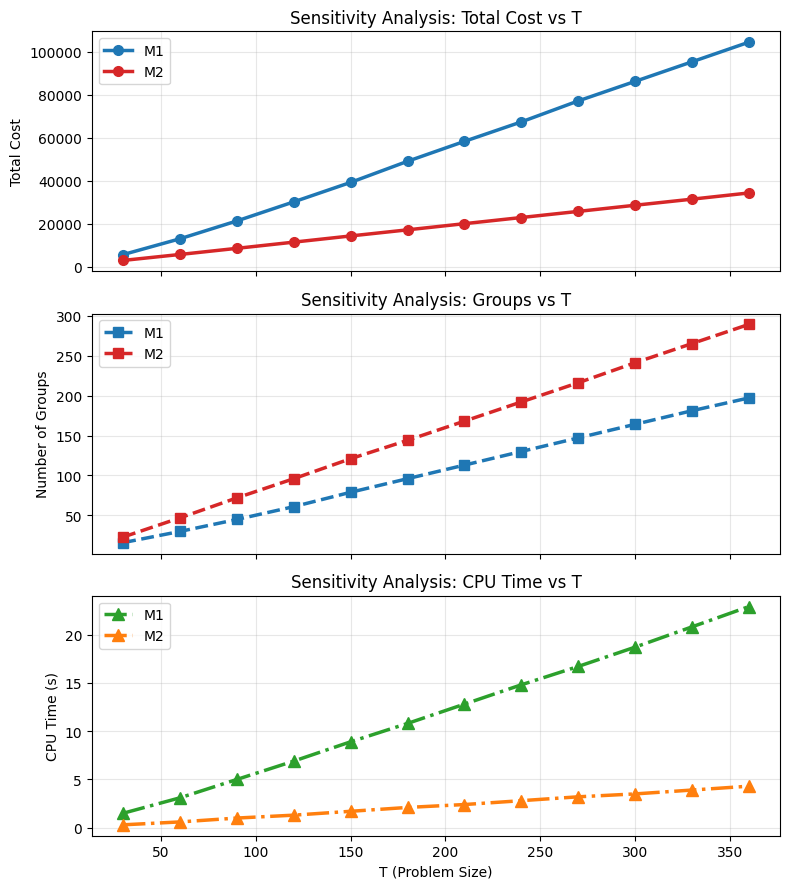

In [10]:
# sensitivity analysis for problem size: T
import matplotlib.pyplot as plt
import numpy as np

# ===== 数据 =====
T = np.arange(30, 361, 30)

# M1
total_cost_M1 = np.array([5599.83, 12953.83, 21253.83, 30127.00, 39180.17, 48998.83, 58263.83, 67323.00, 77075.83, 86171.17, 95273.50, 104400.50])
num_groups_M1 = np.array([16, 30, 45, 61, 79, 96, 113, 130, 147, 164, 181, 197])
cpu_time_M1   = np.array([1.5, 3.1, 5.0, 6.9, 8.9, 10.8, 12.8, 14.8, 16.7, 18.7, 20.8, 22.9])

# M2
total_cost_M2 = np.array([2870.50, 5647.83, 8496.67, 11378.67, 14259.83, 17101.83, 19966.67, 22832.00, 25677.67, 28540.67, 31368.17, 34259.17])
num_groups_M2 = np.array([23, 47, 72, 96, 121, 144, 168, 192, 216, 241, 265, 289])
cpu_time_M2   = np.array([0.3, 0.6, 1.0, 1.3, 1.7, 2.1, 2.4, 2.8, 3.2, 3.5, 3.9, 4.3])
 
plt.rcParams["font.family"] = "DejaVu Sans"

# ===== 三个子图 =====
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)

# ========== 图1：Total Cost ==========
axes[0].plot(T, total_cost_M1, "o-", color="#1f77b4", linewidth=2.5, markersize=7, label="M1")
axes[0].plot(T, total_cost_M2, "o-", color="#d62728", linewidth=2.5, markersize=7, label="M2")
axes[0].set_ylabel("Total Cost")
axes[0].set_title("Sensitivity Analysis: Total Cost vs T")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# ========== 图2：Number of Groups ==========
axes[1].plot(T, num_groups_M1, "s--", color="#1f77b4", linewidth=2.5, markersize=7, label="M1")
axes[1].plot(T, num_groups_M2, "s--", color="#d62728", linewidth=2.5, markersize=7, label="M2")
axes[1].set_ylabel("Number of Groups")
axes[1].set_title("Sensitivity Analysis: Groups vs T")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

# ========== 图3：CPU Time ==========
axes[2].plot(T, cpu_time_M1, "^-.", color="#2ca02c", linewidth=2.5, markersize=8, label="M1")
axes[2].plot(T, cpu_time_M2, "^-.", color="#ff7f0e", linewidth=2.5, markersize=8, label="M2")
axes[2].set_xlabel("T (Problem Size)")
axes[2].set_ylabel("CPU Time (s)")
axes[2].set_title("Sensitivity Analysis: CPU Time vs T")
axes[2].legend(loc="upper left")
axes[2].grid(True, alpha=0.3)

# 可选：CPU 对数轴看线性度
# axes[2].set_yscale("log")

plt.tight_layout()
plt.show()
